# ¿La presión arterial sube siempre con la edad?

**Capítulo del curso:** Modelado de datos (Open-Ended Project 4)

Comparo la presión sistólica según la edad en dos poblaciones: 100 personas de EE. UU. (NHANES) y 71 del pueblo
yanomami, que vive casi aislado en la Amazonía y consume muchísima menos sal. Ajusto una regresión lineal
`presión ~ edad` en cada una y comparo la pendiente y el R².

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = Path("figuras")
FIG.mkdir(exist_ok=True)
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [2]:
eeuu = pd.read_csv("datos/blood-pressure-usa.csv")
yanomami = pd.read_csv("datos/blood-pressure-yanomami.csv")

# Cada persona de EE. UU. tiene tres mediciones: uso su promedio.
eeuu["bp"] = eeuu[["bp1", "bp2", "bp3"]].mean(axis=1)
eeuu.head()

,age,bp1,bp2,bp3,bp
0,46,122,129,122,124.333333
1,43,113,116,111,113.333333
2,29,102,107,105,104.666667
3,12,100,102,102,101.333333
4,9,112,138,94,114.666667


In [3]:
def ajustar(df, nombre):
    modelo = LinearRegression().fit(df[["age"]], df["bp"])
    r2 = r2_score(df["bp"], modelo.predict(df[["age"]]))
    return {"población": nombre, "pendiente (mmHg/año)": modelo.coef_[0],
            "intercepto (mmHg)": modelo.intercept_, "R²": r2, "n": len(df), "modelo": modelo}

resultados = [ajustar(eeuu, "EE. UU."), ajustar(yanomami, "Yanomami")]
pd.DataFrame(resultados).drop(columns="modelo").round(3)

,población,pendiente (mmHg/año),intercepto (mmHg),R²,n
0,EE. UU.,0.741,93.370,0.472,100
1,Yanomami,-0.004,95.475,0.000,71


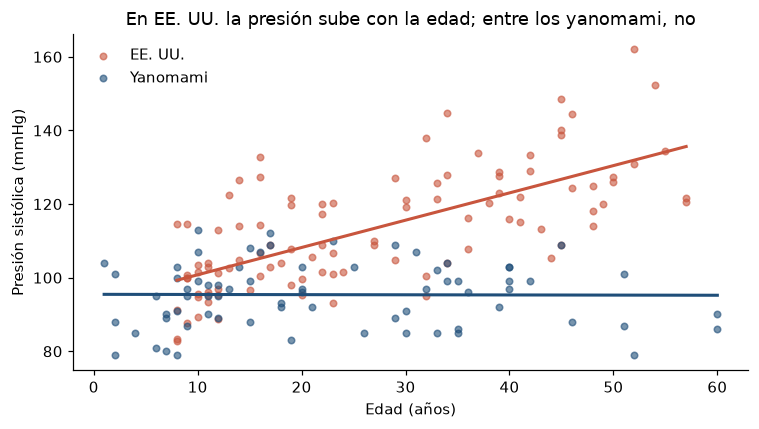

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
for df, res, color in [(eeuu, resultados[0], "#c8553d"), (yanomami, resultados[1], "#1f4e79")]:
    ax.scatter(df["age"], df["bp"], s=18, alpha=0.6, color=color, label=res["población"])
    x = pd.DataFrame({"age": [df["age"].min(), df["age"].max()]})
    ax.plot(x["age"], res["modelo"].predict(x), color=color, lw=2)
ax.set_xlabel("Edad (años)")
ax.set_ylabel("Presión sistólica (mmHg)")
ax.set_title("En EE. UU. la presión sube con la edad; entre los yanomami, no")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "presion-vs-edad.png", bbox_inches="tight")
plt.show()

## Conclusiones

- En **EE. UU.** la presión sube unos **0,74 mmHg por año** de edad y la edad explica casi la mitad de la variación
  (R² ≈ 0,47).
- Entre los **yanomami** la pendiente es prácticamente cero (−0,004 mmHg por año, R² ≈ 0): su presión se mantiene
  alrededor de 95 mmHg a cualquier edad.
- Así que **no**: que la presión suba con la edad no es una ley biológica universal, al menos en estos datos.

### ¿Prueba esto que la sal es la causa?

No. Es un estudio observacional y hay muchos factores de confusión: actividad física, dieta en general (azúcar,
alimentos procesados), peso corporal, alcohol y tabaco, genética, estrés y acceso a la medicina. Además, las muestras
son pequeñas y se midieron con métodos distintos. Para hablar de causa haría falta un experimento controlado o un
estudio que ajuste por esas variables, como el INTERSALT.